## Listes de 9 questions

Quand et comment les clients commandent-ils généralement ?  

Quels produits faut-il mettre en avant le samedi ?  

Quels autres produits les clients commandent-ils fréquemment avec du chocolat ?  

Quels sont les principaux profils de clients : acheteurs nocturnes, acheteurs occasionnels ou accros au  panier ?

Quel article les clients ajoutent-ils en premier à leur panier ?

Quels produits ont le plus de chances d’être commandés à nouveau ?

Les clients commandent-ils en moyenne plus de nourriture pour chats le matin que de nourriture pour chiens le soir ?

Existe-t-il une corrélation entre l’heure de la dernière commande et la probabilité de recommander un produit ?

Peut-on prédire si un produit sera commandé à nouveau par un client lors de sa prochaine visite ?

Importation des modules

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

Ouverture des fichiers 

In [10]:
df_aisles = pd.read_csv("./datasets/aisles.csv")
df_departments = pd.read_csv("./datasets/departments.csv")
df_order_products = pd.read_csv("./datasets/order_products.csv")
df_orders = pd.read_csv("./datasets/orders.csv")
df_products = pd.read_csv("./datasets/products.csv")

On enleve 1 colonnes qui est NaN

In [11]:
df_orders = df_orders.drop(columns=["days_since_prior_order"])
df_orders.columns = ["order_id", "user_id", "order_number", "order_dow", "order_hour_of_day", "days_since_prior_order"]

Vérifications qu'il n'y a pas de valeurs nul.

In [12]:
df_aisles.isnull().sum()
df_departments.isnull().sum()
df_order_products.isnull().sum()
df_orders.isnull().sum()
df_products.isnull().sum()

product_id       0
product_name     0
aisle_id         0
department_id    0
dtype: int64

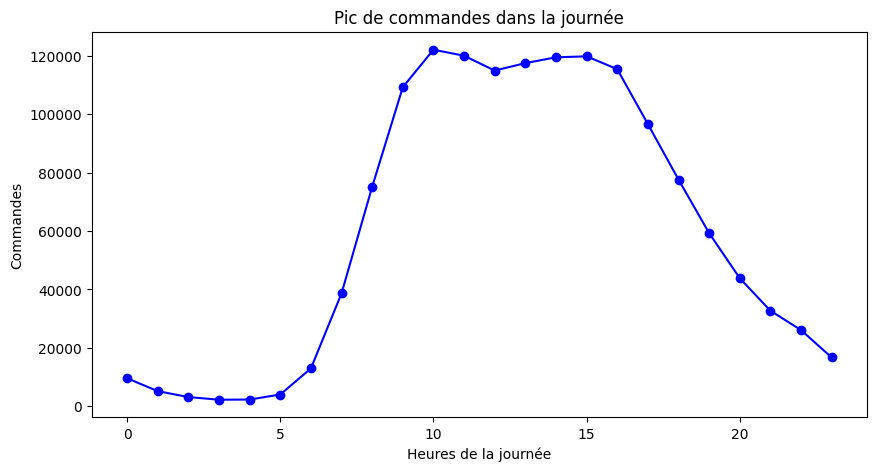

In [13]:
df_orders_hour = df_orders["order_hour_of_day"].value_counts().sort_index()
df_orders_day = df_orders["days_since_prior_order"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.plot(df_orders_hour.index, df_orders_hour.values, marker="o", color="blue")
plt.title("Pic de commandes dans la journée")
plt.xlabel("Heures de la journée")
plt.ylabel("Commandes")
plt.show()

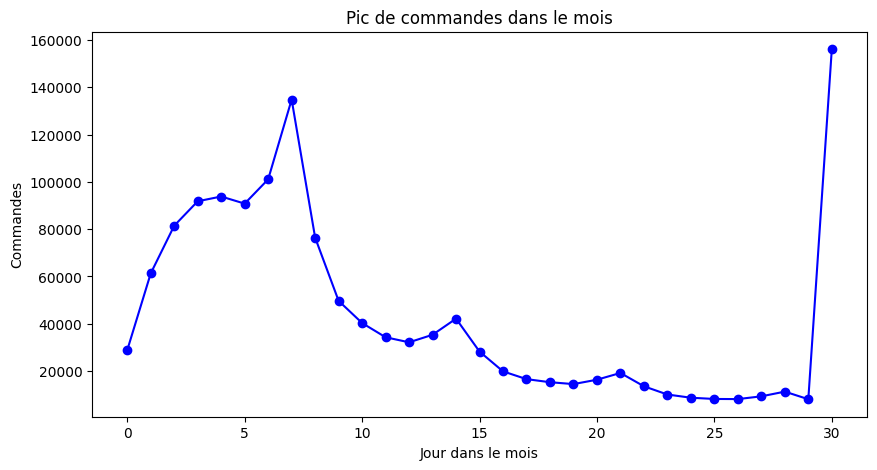

In [22]:
df_orders_hour = df_orders["order_hour_of_day"].value_counts().sort_index()
df_orders_day = df_orders["days_since_prior_order"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.plot(df_orders_day.index, df_orders_day.values, marker="o", color="blue")
plt.title("Pic de commandes dans le mois")
plt.xlabel("Jour dans le mois")
plt.ylabel("Commandes")
plt.show()

Quand et comment les clients commandent-ils généralement ?  

Donc on en conclus que : 

Le pic matinal : L'affluence maximale se situe autour de 10h du matin. Les clients ont donc tendance à organiser leurs courses en ligne en milieu de matinée plutôt que le soir.

La routine hebdomadaire : On observe des rebonds de commandes très nets tous les 7, 14 et 21 jours. Cela met en lumière une routine bien ancrée chez les familles, qui effectuent leurs achats de manière très régulière, semaine après semaine.

Le grand ravitaillement mensuel : Le pic le plus important se trouve à 30 jours. Il correspond aux clients qui font un gros "plein" une fois par mois (souvent après la paie), mais il représente aussi un plafond technique de la base de données qui regroupe toutes les commandes espacées de 30 jours et plus.
